# Mixed-state WH entropy

See [Tutorial.ipynb](Tutorial.ipynb) for installation and the shared workflow.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cirq
from pathlib import Path
import tempfile

from cirq_sic.measurements import Measurement, sic_povm, wh_measurement
from cirq_sic.workflow import (
    Experiment, ExperimentResult, tomography_experiment, entropy_experiment,
    wh_entropy_experiment, sky_ground_experiment, triple_product_experiment,
    compile_circuit,
)
from cirq_sic.analysis import stabilizer_renyi_entropy, born_rule_diagnostics
from cirq_sic.triples import triple_products, triple_product_state_space, sic_state_constraints

rng = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Cirq', cirq.__version__)

Cirq 1.3.0


## 2. WH entropy, including mixed states

For a cyclic $d$-dimensional WH operator basis, write
$\chi_{ab}=\mathrm{Tr}(\rho D_{ab})$ and $\gamma=\mathrm{Tr}(\rho^2)$.
The purity-corrected Rényi-2 diagnostic is

$$M_2(\rho)=-\log_2\frac{\sum_{ab}|\chi_{ab}|^4}{d\gamma}.$$

A direct two-copy experiment prepares $\rho\otimes\rho^*$ and measures
$s_{ab}=\mathrm{Tr}(\rho D_{ab}\rho D_{ab}^\dagger)/d$.
Discrete Fourier Parseval gives $\gamma=ds_{00}$ and
$M_2=-\log_2(\sum_{ab}s_{ab}^2/s_{00})$. No tomographic inverse is needed.
The ability to prepare the conjugate state is an assumption: this is not a
universal conjugation channel for an unknown input.

For mixed inputs, preparation uses a unitary purification and unmeasured
environment qubits. They are separate from the measurement ancillas.

In [2]:
qubit_sic = sic_povm(2)
magic = qubit_sic.states[:, 0]
rho_magic = np.outer(magic, magic.conj())
rho_mixed = 0.65 * rho_magic + 0.35 * np.eye(2) / 2
entropy_plan = wh_entropy_experiment(rho_mixed)
entropy_exact = entropy_plan.analyze(entropy_plan.simulate())
entropy_sample = entropy_plan.analyze(entropy_plan.run(repetitions=16000, seed=12))
print('Purity (exact / sampled):', entropy_exact['purity'], entropy_sample['purity'])
print('M2 (exact / sampled):', entropy_exact['entropy'], entropy_sample['entropy'])
assert np.isclose(entropy_exact['entropy'],
                  stabilizer_renyi_entropy(rho_mixed, basis='wh', mixed=True))

Purity (exact / sampled): 0.7112500000000004 0.71625
M2 (exact / sampled): 0.4250422280009031 0.43121339171959205


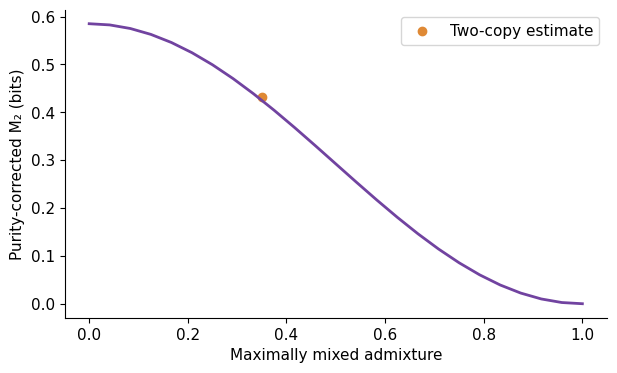

In [3]:
mixing = np.linspace(0, 1, 25)
curve = [stabilizer_renyi_entropy((1-t)*rho_magic + t*np.eye(2)/2,
                                 basis='wh', mixed=True) for t in mixing]
fig, ax = plt.subplots()
ax.plot(mixing, curve, color='#7143a0', lw=2)
ax.scatter([.35], [entropy_sample['entropy']], color='#df8935', label='Two-copy estimate')
ax.set(xlabel='Maximally mixed admixture', ylabel='Purity-corrected M₂ (bits)')
ax.legend()
plt.show()
assert abs(curve[-1]) < 1e-10

The mixed-state extension is a diagnostic, not a faithful magic measure on
the convex hull of stabilizer states. Even $\rho=\mathrm{diag}(0.75,0.25)$ has
positive $M_2$. Finite-shot collision probabilities, ratios, and logarithms are
biased; a small negative estimate is not clipped to zero. If the identity
outcome is never observed, the ratio cannot be estimated and analysis raises.

`basis='pauli'` means tensor-product qubit Paulis. `basis='wh'` means one cyclic
qudit. They agree for a single qubit but differ for $d\ge4$; embedding a qudit in
qubits does not change which operator basis defines your diagnostic.
`entropy_experiment` supplies a complementary route: measure an IC POVM,
reconstruct the state, then evaluate a chosen Rényi order and basis. For sampled
or mixed inputs use `mixed=True` and inspect the reconstruction/projection.

In [4]:
pauli_plan = entropy_experiment(rho_mixed, qubit_sic, basis='pauli', mixed=True)
pauli_report = pauli_plan.analyze(pauli_plan.simulate())
assert np.isclose(pauli_report['entropy'], entropy_exact['entropy'])
print('Tomographic route:', pauli_report['entropy'])

Tomographic route: 0.4250422280009035


In [5]:
diagonal_stabilizer_mixture = np.diag([.75, .25])
value = stabilizer_renyi_entropy(diagonal_stabilizer_mixture, mixed=True)
assert value > 0
print('A free convex mixture with positive diagnostic:', value)
for d in [2, 3, 4, 5]:
    plan = wh_entropy_experiment(np.eye(d)/d)
    report = plan.analyze(plan.simulate())
    assert abs(report['entropy']) < 1e-10
    assert np.isclose(report['purity'], 1/d)
print('Maximally mixed endpoints checked in dimensions 2–5.')

A free convex mixture with positive diagnostic: 0.2344652536370228


Maximally mixed endpoints checked in dimensions 2–5.
